# Localising post-hoc watermarks — final summary

Team BlitzTeam, European AI Championship Paris (21–22 Nov 2026), task 1.
**Final public leaderboard score: 0.739** (14th of 42). All numbers below are 5-fold cross-validation (CV) on the 510
train images unless marked *public*; CV predicted the public score within ±0.006 throughout.

**Task.** Each 512×512 image carries a PixelSeal, TrustMark or StegaStamp watermark (known message). Edits removed or
added it in parts. Output a 128×128 mask (1 = watermarked); score per image = (IoU watermarked + IoU clean) / 2.
- *full* images: watermarked everywhere except edited holes;
- *partial* images: only an outpainted rectangle or a transplanted object is watermarked.

**Final pipeline** (`make_sub3.py`):
1. **Gate** full / partial: mean of our own map (TrustMark, StegaStamp) or whole-image decode (PixelSeal).
2. **Map**: ensemble of decoder-based segmenters (`e2e.py`): the old ensemble (weight 0.2) + the largest
   *real-domain synthetic* (RS) models, trained on 32k–64k synthetic images built from the dataset's own images.
3. **Partial images**: decoder-verified **box** if found → else **zoom rectangle** (magnified tiles) → else **SAM**
   outline at the map peak if it agrees with the map → else the post-processed map.
4. **Post-processing** per regime (smoothing, fill / largest component, threshold), all thresholds fit on training folds.

In [1]:
import sys, re, glob, os
sys.path.insert(0, ".."); os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import data
from evalmaps import load_maps
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
METH = ["pixelseal", "trustmark", "stegastamp"]; SHORT = {"pixelseal": "PixelSeal", "trustmark": "TrustMark", "stegastamp": "StegaStamp"}
FINAL = {"pixelseal": "ensHP_pixelseal", "trustmark": "ensH_trustmark", "stegastamp": "ensHP_stegastamp"}
print("ok")

ok


## 1. Score progression over the competition

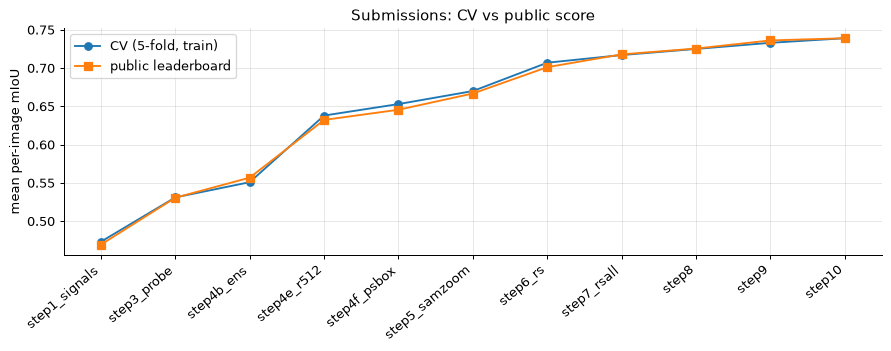

,step,cv,public
0,step1_signals,0.4733,0.4695
1,step3_probe,0.5311,0.5307
2,step4b_ens,0.5510,0.5569
3,step4e_r512,0.6380,0.6323
4,step4f_psbox,0.6530,0.6456
5,step5_samzoom,0.6700,0.6668
6,step6_rs,0.7070,0.7012
7,step7_rsall,0.7170,0.7179
8,step8,0.7250,0.7255
9,step9,0.7330,0.7361


In [2]:
rows = []
for line in open("submissions.md"):
    if not line.startswith("| 2026"): continue
    c = [x.strip() for x in line.split("|")]
    cv = re.match(r"([0-9.]+)", c[4]); pub = re.match(r"([0-9.]+) \(public", c[5])
    if cv and pub:
        rows.append(dict(step=os.path.basename(c[2]).replace("sub_", "").replace(".pt", ""), cv=float(cv.group(1)), public=float(pub.group(1))))
S = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(S)); ax.plot(x, S.cv, "o-", label="CV (5-fold, train)"); ax.plot(x, S.public, "s-", label="public leaderboard")
ax.set_xticks(x); ax.set_xticklabels(S.step, rotation=40, ha="right"); ax.set_ylabel("mean per-image mIoU"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Submissions: CV vs public score"); plt.tight_layout(); plt.show()
S.round(4)

What drove each jump (details in `submissions.md`): decoder-feature probes (0.53) → end-to-end decoder segmenter on
FLUX-VAE synthetic data at 512 px + decoder-verified boxes (0.63–0.65) → zoom + SAM for partial images (0.667) →
**real-domain synthetic (RS) data** (0.701) → many and larger RS models + map gate (0.718 → 0.736) → largest-model
ensembles + RS-seeded StegaStamp boxes (**0.739**).

## 2. Final per-method results (held-out CV of the whole pipeline)

In [3]:
def category(g, full):
    if full:
        fr = (~g).mean(); return "full", ("hole <3%" if fr < .03 else "hole 3-10%" if fr < .1 else "hole >10%")
    ys, xs = np.nonzero(g); rect = len(ys) and g[ys.min():ys.max()+1, xs.min():xs.max()+1].mean() > .98
    fr = g.mean(); return ("rectangle" if rect else "object"), ("wm <2%" if fr < .02 else "wm 2-8%" if fr < .08 else "wm >8%")
R = []
for m in METH:
    z = np.load(f"results/final/held_{m}.npz"); G = z["G"].astype(bool)
    for n, h, fl, g in zip(z["names"], z["held"], z["full"], G):
        cat, size = category(g, fl); R.append(dict(method=SHORT[m], name=n, cat=cat, size=size, score=h))
R = pd.DataFrame(R)
print("overall CV:", round(R.score.mean(), 4))
T = R.pivot_table(index="method", columns="cat", values="score", aggfunc="mean"); T["all"] = R.groupby("method").score.mean()
T.round(3)

overall CV: 0.7387


cat,full,object,rectangle,all
method,,,,
PixelSeal,0.688,0.743,0.680,0.700
StegaStamp,0.757,0.834,0.715,0.765
TrustMark,0.691,0.764,0.857,0.751


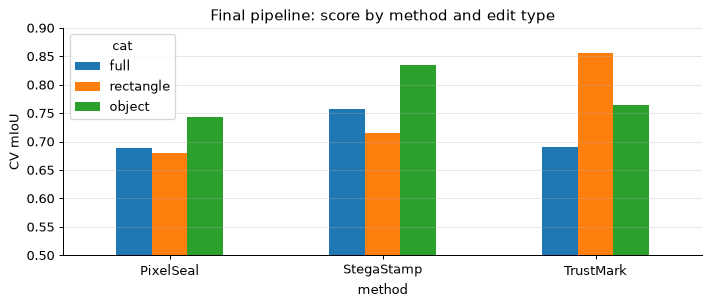

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
T[["full", "rectangle", "object"]].plot.bar(ax=ax, rot=0); ax.set_ylim(.5, .9); ax.set_ylabel("CV mIoU")
ax.set_title("Final pipeline: score by method and edit type"); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## 3. Where the remaining points are lost

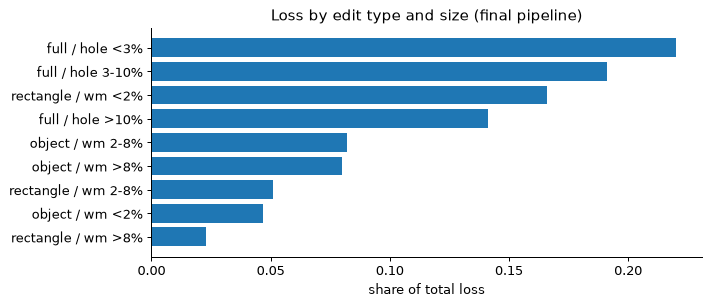

images  score  share of loss
cat       size                                    
full      hole <3%        75  0.609          0.220
          hole 3-10%      93  0.727          0.191
rectangle wm <2%          57  0.613          0.166
full      hole >10%       87  0.785          0.141
object    wm 2-8%         47  0.768          0.082
          wm >8%          64  0.833          0.080
rectangle wm 2-8%         39  0.827          0.051
object    wm <2%          16  0.606          0.047
rectangle wm >8%          32  0.905          0.023

In [5]:
N = len(R); R["loss"] = (1 - R.score) / N
L = R.groupby(["cat", "size"]).agg(images=("score", "size"), score=("score", "mean"), loss=("loss", "sum")).sort_values("loss", ascending=False)
L["share of loss"] = (L.loss / R.loss.sum()).round(3)
fig, ax = plt.subplots(figsize=(8, 3.5))
lab = [f"{a} / {b}" for a, b in L.index]; ax.barh(lab[::-1], L["share of loss"][::-1]); ax.set_xlabel("share of total loss")
ax.set_title("Loss by edit type and size (final pipeline)"); plt.tight_layout(); plt.show()
L.drop(columns="loss").round(3)

Full images with **tiny holes (< 3 %)** and **tiny outpainted rectangles (< 2 %)** remain the largest losses: each image
counts equally, so a 1 % region weighs as much as half an image. Thresholds and post-processing were saturated
(oracle best threshold per image: +0.04); only better maps — mostly from more and larger RS models — moved them.

## 4. Scaling: more synthetic training images → better full-image maps

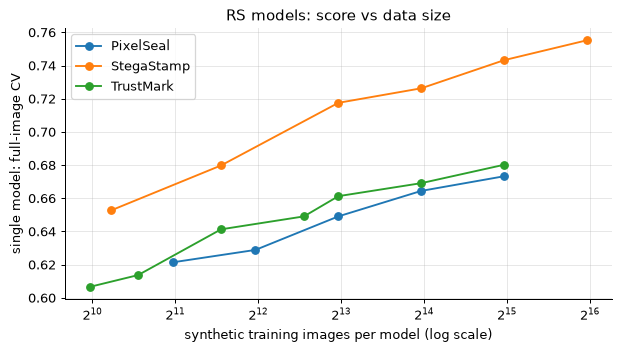

count   mean    max
method     N                         
PixelSeal  2000       2  0.621  0.622
           4000       1  0.629  0.629
           8000      14  0.649  0.658
           16000      3  0.664  0.668
           32000      3  0.673  0.675
StegaStamp 1200       1  0.653  0.653
           3000       1  0.680  0.680
           8000       8  0.718  0.723
           16000      1  0.726  0.726
           32000     11  0.743  0.749
           64000      3  0.755  0.759
TrustMark  1000       1  0.607  0.607
           1500       3  0.614  0.628
           3000       1  0.641  0.641
           6000       1  0.649  0.649
           8000      10  0.661  0.665
           16000      3  0.669  0.674
           32000      4  0.680  0.689

In [6]:
pts = []
for f in glob.glob("research/out/realsynth_prod_*.log"):
    txt = open(f).read(); head = re.search(r"^(\w+) recipe .*? steps (\d+) N (\d+)", txt, re.M); ft = re.search(r"^fine-tuned: full CV ([0-9.]+)", txt, re.M)
    if head and ft and not re.search(r"_L[A-Z]\.log$", f):
        pts.append(dict(method=SHORT[head.group(1)], N=int(head.group(3)), cv=float(ft.group(1))))
P = pd.DataFrame(pts)
fig, ax = plt.subplots(figsize=(7, 4))
for m, d in P.groupby("method"):
    agg = d.groupby("N").cv.agg(["mean", "max", "count"]); ax.plot(agg.index, agg["mean"], "o-", label=m)
ax.set_xscale("log", base=2); ax.set_xlabel("synthetic training images per model (log scale)"); ax.set_ylabel("single model: full-image CV")
ax.set_title("RS models: score vs data size"); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
P.groupby(["method", "N"]).cv.agg(["count", "mean", "max"]).round(3)

Every doubling of the RS data gave roughly +0.01 on full images (StegaStamp: 0.72 → 0.726 → 0.742 → 0.752 for 8k → 64k).

## 5. Examples on train images (held-out maps): image, ground truth, final probability map

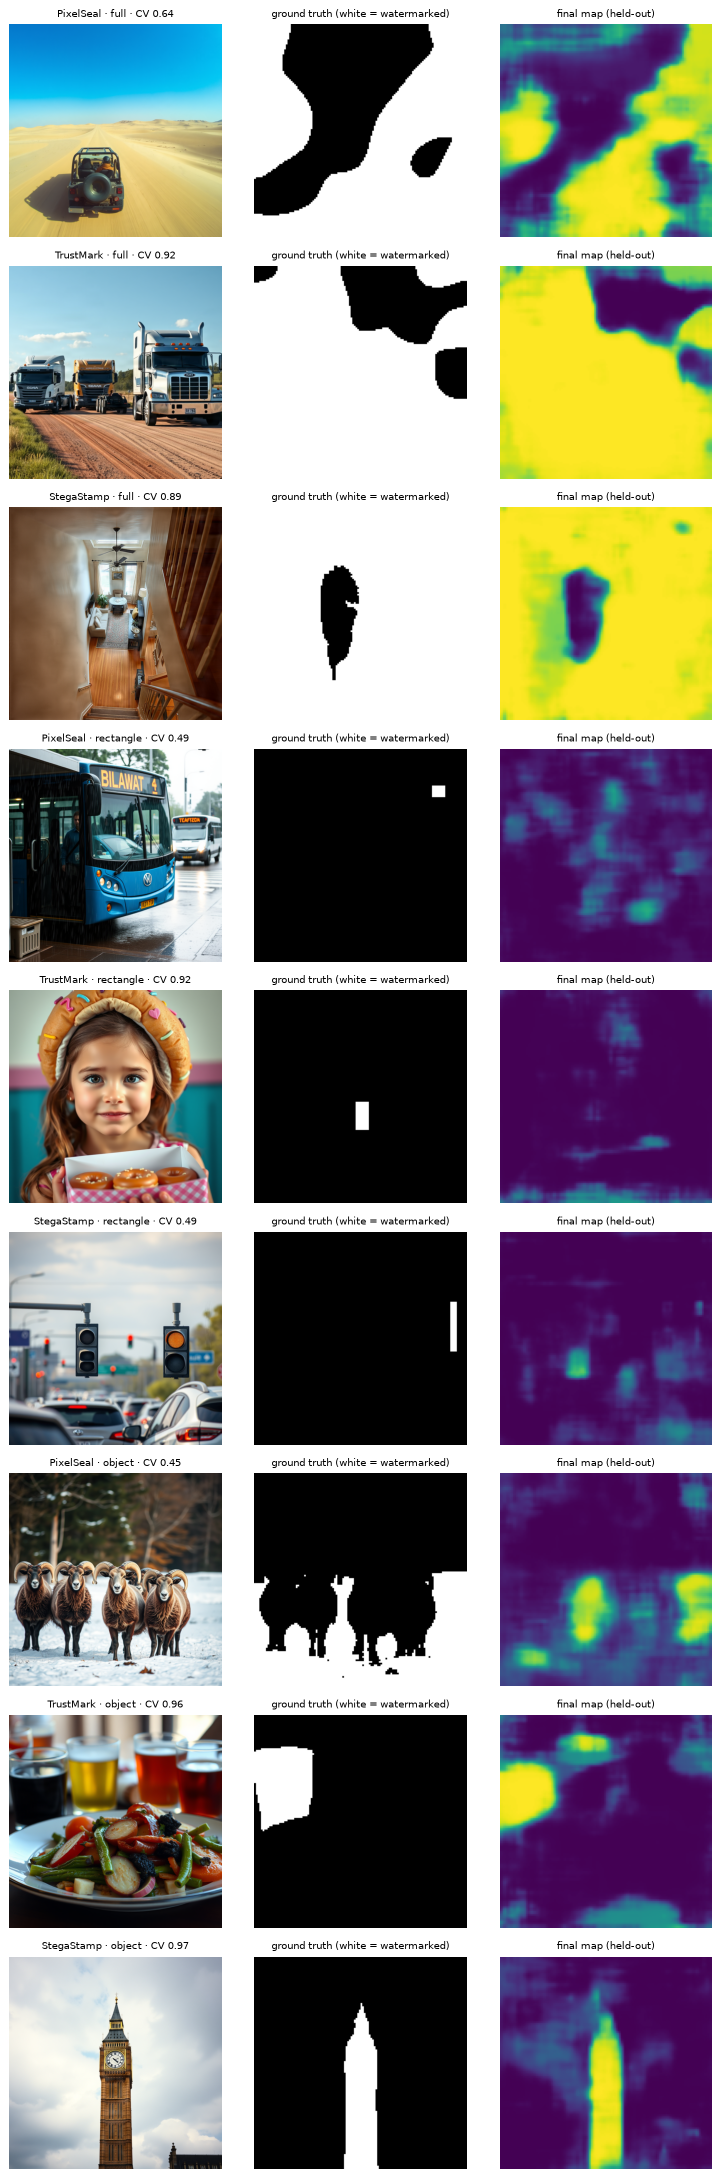

In [7]:
ds = data.load_split("train"); idx = {ds.meta[i]["image_name"]: i for i in range(len(ds))}
maps = {}
for m in METH:
    n, P_ = load_maps(FINAL[m], "train"); maps.update(zip(n, P_))
rng = np.random.default_rng(3); picks = []
for cat in ("full", "rectangle", "object"):
    for m in METH:
        cand = R[(R.cat == cat) & (R.method == SHORT[m])]
        picks.append(cand.sample(1, random_state=int(rng.integers(1e6))).iloc[0])
fig, ax = plt.subplots(len(picks), 3, figsize=(8.5, 2.7 * len(picks)))
for r, p in enumerate(picks):
    it = ds[idx[p["name"]]]
    ax[r, 0].imshow(it["image"]); ax[r, 0].set_title(f'{p["method"]} · {p["cat"]} · CV {p["score"]:.2f}', fontsize=8)
    ax[r, 1].imshow(it["mask128"], cmap="gray", vmin=0, vmax=1); ax[r, 1].set_title("ground truth (white = watermarked)", fontsize=8)
    ax[r, 2].imshow(maps[p["name"]], vmin=0, vmax=1, cmap="viridis"); ax[r, 2].set_title("final map (held-out)", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 6. Final submission on test images (`results/sub_step10.pt`)

1020 test masks | mean watermarked fraction 0.498


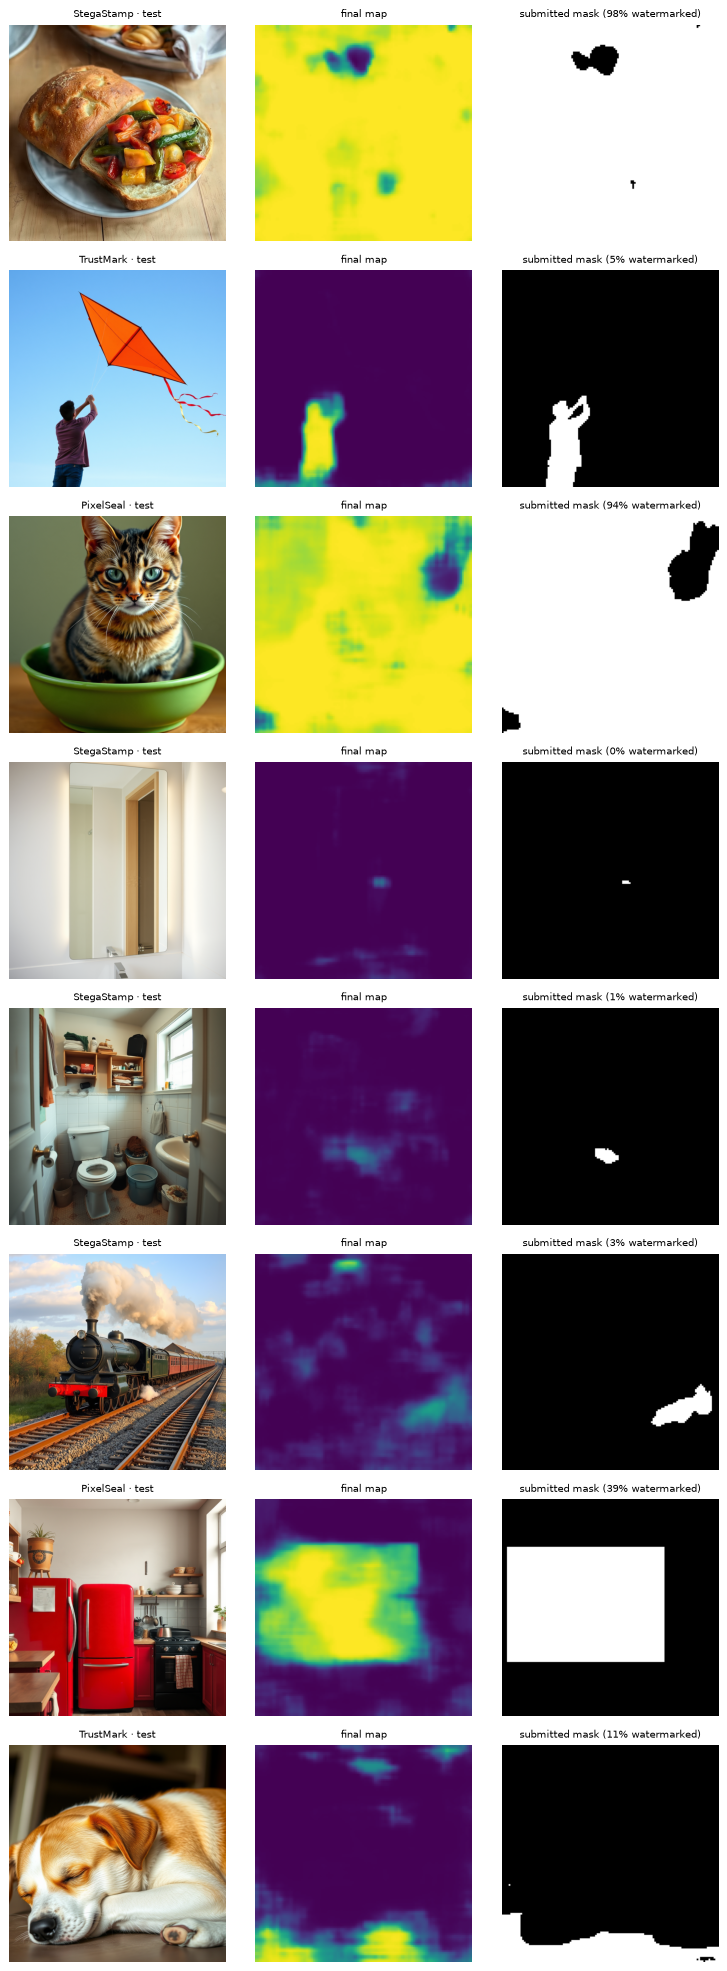

In [8]:
sub = torch.load("results/sub_step10.pt", weights_only=True); M = dict(zip(sub["image_names"], sub["masks"].numpy()))
te = data.load_split("test"); tmeta = {te.meta[i]["image_name"]: i for i in range(len(te))}
print(len(M), "test masks | mean watermarked fraction", round(float(np.mean([m.mean() for m in M.values()])), 3))
tmaps = {}
for m in METH:
    n, P_ = load_maps(FINAL[m], "test"); tmaps.update(zip(n, P_))
names = list(M); sel = np.random.default_rng(7).choice(len(names), 8, replace=False)
fig, ax = plt.subplots(8, 3, figsize=(8.5, 22))
for r, k in enumerate(sel):
    n = names[k]; it = te[tmeta[n]]
    ax[r, 0].imshow(it["image"]); ax[r, 0].set_title(f'{SHORT[it["method"]]} · test', fontsize=8)
    ax[r, 1].imshow(tmaps[n], vmin=0, vmax=1, cmap="viridis"); ax[r, 1].set_title("final map", fontsize=8)
    ax[r, 2].imshow(M[n], cmap="gray", vmin=0, vmax=1); ax[r, 2].set_title(f"submitted mask ({M[n].mean():.0%} watermarked)", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 7. What did not work (measured, do not repeat)

| Idea | Result |
|---|---|
| TruFor (forgery localiser), autoencoder reconstruction error | AUC on holes 0.44–0.61 (≈ chance) |
| Pixel-level matched filter with the re-embedded known-message pattern | AUC 0.51 |
| Decoder per-location agreement maps (incl. shift-and-stitch) | AUC 0.61–0.64, below the learned maps |
| DINOv2 image features | CV 0.45 |
| SD2-inpainted synthetic holes | worse than pasted / restored holes (0.537 vs 0.592) |
| 128×128 output head, 768 px input, low-resolution RS models | worse |
| fp32 vs bf16, Lovász loss, no-flip, scale augmentation, long pretraining | ≈ 0 or worse |
| Per-image expected-IoU thresholds, component rules, never-empty hole | ≤ +0.005 |

**Main lesson:** the score was limited by how closely the synthetic training data matched the real images.
Building it from the dataset's own images (RS) and scaling it up gave most of the progress; tweaks to the model and
post-processing gave almost nothing.